# Lab 6 — Stage V

## Activity 1 — TF-IDF and Logistic Regression

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

df = pd.read_csv("app_store_reviews.csv", sep=";")
df = df.loc[df["star"].isin([1, 2, 4, 5]), ["review", "star"]].dropna().drop_duplicates(subset=["review"]).copy()
df["label"] = df["star"].apply(lambda star: "negative" if star <= 2 else "positive")

X_train, X_test, y_train, y_test = train_test_split(
    df["review"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

metrics = pd.DataFrame(classification_report(
    y_test, y_pred, labels=["negative", "positive"], output_dict=True, zero_division=0
)).T.loc[["negative", "positive"], ["precision", "recall", "f1-score", "support"]]
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
display(metrics.round(3))

Accuracy: 0.682


,precision,recall,f1-score,support
negative,0.667,0.667,0.667,21.0
positive,0.696,0.696,0.696,23.0


## Activity 2 — Confusion Matrix

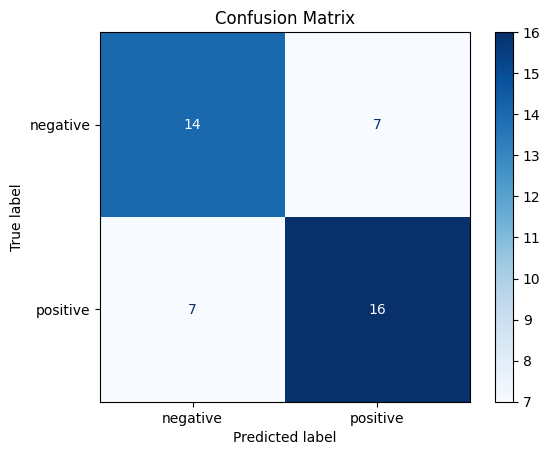

In [2]:
labels = ["negative", "positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

## Activity 3 — Misclassified Reviews

In [3]:
probabilities = pipeline.predict_proba(X_test).max(axis=1)
misclassified = pd.DataFrame({
    "text": X_test.to_numpy(),
    "true_label": y_test.to_numpy(),
    "predicted_label": y_pred,
    "predicted_probability": probabilities
})
misclassified = misclassified[
    misclassified["true_label"] != misclassified["predicted_label"]
].sort_values("predicted_probability", ascending=False)
display(misclassified.head(5).reset_index(drop=True).round(3))

,text,true_label,predicted_label,predicted_probability
0,"The user interface is confusing, I can't figur...",negative,positive,0.608
1,"Update brought in some handy features, especia...",negative,positive,0.586
2,Simple and user-friendly.,negative,positive,0.586
3,Slow customer support.,negative,positive,0.570
4,Search results inaccurate.,negative,positive,0.566


## Activity 4 — Class Balancing

In [4]:
display(df["label"].value_counts().rename_axis("class").reset_index(name="count"))

balanced_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])
balanced_pipeline.fit(X_train, y_train)
balanced_pred = balanced_pipeline.predict(X_test)

comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score"],
    "Original": [
        precision_score(y_test, y_pred, pos_label="negative", zero_division=0),
        recall_score(y_test, y_pred, pos_label="negative", zero_division=0),
        f1_score(y_test, y_pred, pos_label="negative", zero_division=0)
    ],
    "Balanced": [
        precision_score(y_test, balanced_pred, pos_label="negative", zero_division=0),
        recall_score(y_test, balanced_pred, pos_label="negative", zero_division=0),
        f1_score(y_test, balanced_pred, pos_label="negative", zero_division=0)
    ]
})
display(comparison.round(3))

,class,count
0,positive,115
1,negative,104


,Metric,Original,Balanced
0,Precision,0.667,0.696
1,Recall,0.667,0.762
2,F1-score,0.667,0.727


## Activity 5 — Negative Review Flagging

In [5]:
feedback = X_test
feedback_predictions = pipeline.predict(feedback)
feedback_probabilities = pipeline.predict_proba(feedback).max(axis=1)

results = pd.DataFrame({
    "review": feedback.to_numpy(),
    "predicted_label": feedback_predictions,
    "confidence": feedback_probabilities,
    "flag_for_support": feedback_predictions == "negative"
})
display(results.loc[results["flag_for_support"]].reset_index(drop=True).round(3))
print("Negative precision:", round(precision_score(y_test, y_pred, pos_label="negative", zero_division=0), 3))
print("Negative recall:", round(recall_score(y_test, y_pred, pos_label="negative", zero_division=0), 3))

,review,predicted_label,confidence,flag_for_support
0,It 's nice that the app recommends nearby attr...,negative,0.548,True
1,Too costly for what you get in the premium ver...,negative,0.504,True
2,The premium subscription unlocks so many usefu...,negative,0.520,True
3,The latest update made the app slower. It used...,negative,0.504,True
4,Useful but needs improvements.,negative,0.553,True
5,"Update made the app laggy and unresponsive, ve...",negative,0.557,True
6,"Update is buggy, constantly showing error mess...",negative,0.549,True
7,"Update brought more bugs, app crashes at rando...",negative,0.595,True
8,"The app is great for planning trips, but it cr...",negative,0.622,True
9,"The UI could be a bit more intuitive, but over...",negative,0.521,True


Negative precision: 0.667
Negative recall: 0.667
